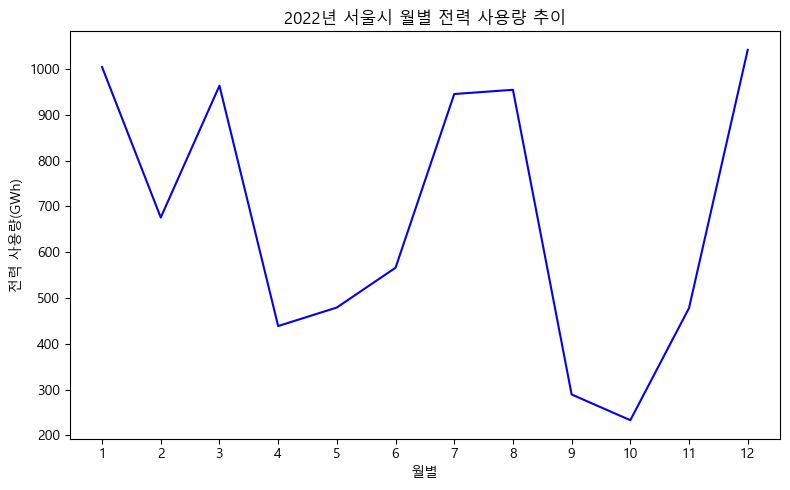

이상치 발생 건수 TOP3:

대전시: 1020
광주시: 937
충청북도: 499


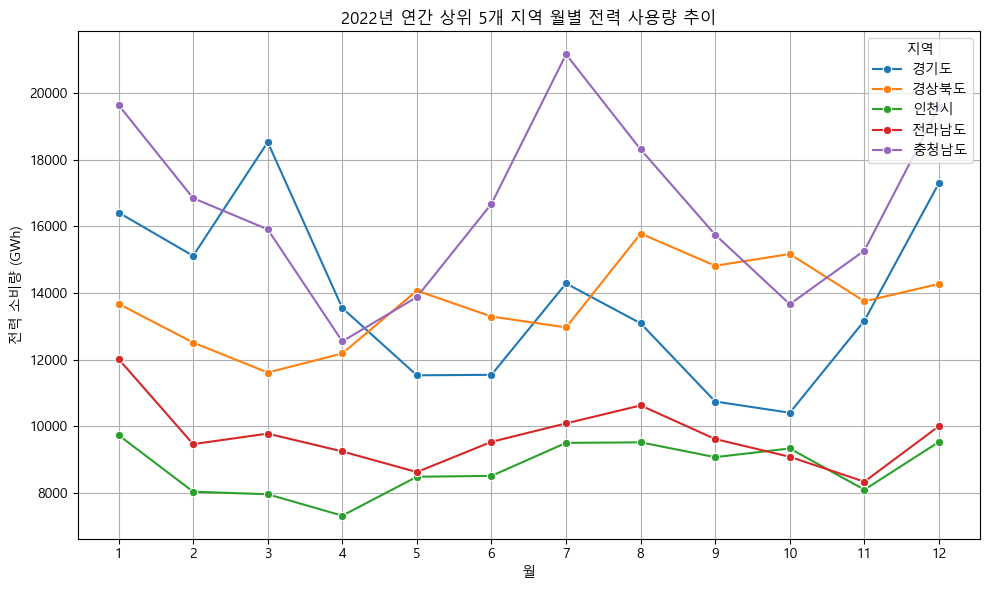

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# 데이터 로드
df = pd.read_csv("2022_광역시별_도별_계량값_1시간(GWh).csv", encoding="cp949")

# 날짜 및 월 파생
df['거래일'] = pd.to_datetime(df['거래일'])
df['월'] = df['거래일'].dt.month

# 1번. 서울시 월별 전력 소비량 분석 (꺾은선 그래프)
seoul = df[df['지역'].str.contains('서울시')]
seoul_monthly = seoul.groupby('월')['계량값'].sum().reset_index()

plt.figure(figsize=(8, 5))
plt.plot(seoul_monthly['월'], seoul_monthly['계량값'], linestyle='-', color='blue')
plt.title("2022년 서울시 월별 전력 사용량 추이")
plt.xlabel("월별")
plt.ylabel("전력 사용량(GWh)")
plt.xticks(range(1, 13))
plt.grid(False)
plt.tight_layout()
plt.show()

# 2번. 월별 평균 초과 이상치 검출 (for-loop 방식)

# 월 파생
df['거래일'] = pd.to_datetime(df['거래일'])
df['월'] = df['거래일'].dt.month

# 이상치 플래그 설정 (for-loop 방식)
outlier_data = []
for (region, month), group in df.groupby(['지역', '월']):
    avg = group['계량값'].mean()
    group = group.copy()
    group['이상치'] = group['계량값'] > (2 * avg)
    outlier_data.append(group)

df_outliers = pd.concat(outlier_data).reset_index(drop=True)

# 이상치 개수 집계 및 정렬
top3 = (
    df_outliers[df_outliers['이상치']]
    .groupby('지역')
    .size()
    .reset_index(name='이상치_개수')
    .sort_values(by='이상치_개수', ascending=False)
    .head(3)
)

print("이상치 발생 건수 TOP3:\n")
for idx, row in top3.iterrows():
    print(f"{row['지역']}: {row['이상치_개수']}")

# 3번. 연간 소비량이 많은 TOP5 지역의 월별 전력 소비 추이
yearly_total = df.groupby('지역')['계량값'].sum().reset_index()
top5_regions = yearly_total.sort_values(by='계량값', ascending=False).head(5)['지역'].tolist()
top5_data = df[df['지역'].isin(top5_regions)]
top5_monthly = top5_data.groupby(['지역', '월'])['계량값'].sum().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=top5_monthly, x='월', y='계량값', hue='지역', marker='o')
plt.title("2022년 연간 상위 5개 지역 월별 전력 사용량 추이")
plt.xlabel("월")
plt.ylabel("전력 소비량 (GWh)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()